# Which receptive fields does one 2-object stimulus drive?

Fix a single 2-object stimulus $(\theta_0, \theta_1)$. For every neuron in a chosen
population compute one number,

$$\text{ratio} \;=\; \frac{\text{its firing rate for THIS stimulus}}
                          {\text{its average 2-object firing rate}}$$

and plot it **at that neuron's own 1-object receptive-field direction**. Above 1 means this
stimulus drives the neuron harder than its average 2-object stimulus does; below 1 means
less. Reading the ring answers the question this notebook exists for: *for which
receptive-field locations does this stimulus cause an increase in firing?*

## The four pieces

**1. The stimulus** — `THETA0_DEG`, `THETA1_DEG`, anywhere on the ring.

**2. The population** — the candidate pool and the retinotopic↔relational **wedge** on the
R² plane.
`BIAS` slides it from purely retinotopic (0) through everything (0.5) to purely relational
(1); the wedges are nested, so mid-sweep values hold far more neurons than the ends. A
neuron enters if it clears the **2-object R² floor** (`MIN_CV_R2`, the cross-validated
explainable variance of a model-agnostic kernel smoother) and the **2-object p-value
ceiling** (`MAX_P`, that quantity's shuffle-null p). Unlike the decoder notebooks nothing is
*drawn* from the wedge — **every** neuron in it is used.

A third filter, `P_THRESH_1OBJ`, is here because of what the figure plots rather than what
selects the population: every dot is *positioned* at the neuron's 1-object RF direction, so a
neuron whose 1-object tuning fit is not significant would contribute a dot at an essentially
random angle. Set it to `None` to keep those neurons anyway.

**3. Rotated replicas** — the construction
`../motor_decoding/population_lib.py` also uses, and the
reason this figure is readable at all. Recorded receptive fields are not uniform on the
ring, so a plot of response-vs-RF-direction built from them alone would have holes and
clumps that say more about which neurons were recorded than about the code. Each real unit
is therefore entered `NUM_REPLICAS` times, rotated by $2\pi k/N$ — and, with
`INCLUDE_REFLECTIONS`, once more per reflection — so the RF directions tile the ring evenly.

A replica is **not new data**. It carries the same trials as its unit, evaluated at the
correspondingly rotated stimulus: copy $c$ responds to $\theta$ through its unit at
$s_c\theta + \text{offset}_c$ and so has effective preferred direction
$\mu_c = s_c(\mu_u - \text{offset}_c)$. Evaluating a rotated copy at the fixed stimulus is
the same as evaluating the real neuron at the counter-rotated stimulus.

**4. The 1-object RF direction** $\mu_u$ — `oneobj_theta_mean` from `xval_units.csv`, the
same 1-object Poisson-cosine phase
[`../model_comparison/rf_orientation.ipynb`](../model_comparison/rf_orientation.ipynb)
measures its 2-object shifts against. It is a **circular** bootstrap mean upstream, so a
neuron whose per-bootstrap angles straddle the 0°/360° seam is not thrown to the opposite
side of the ring.

## How a rate is estimated

A neuron's rate for a queried stimulus is the **swap-invariant circular-Gaussian
kernel-weighted mean of its own recorded 2-object trials** — "some smoothing" of real data,
with no model in between. `SAMPLE_SIGMA_DEG` is the kernel width. Swap-invariance (the
distance to a trial is the smaller of the direct and object-swapped arc-distance sums) means
the estimate does not depend on which object is labelled 0.

## What the denominator is

`BASELINE` picks it, and the three options answer subtly different questions:

| `BASELINE` | the denominator | what the ratio then means |
|---|---|---|
| `'trials'` | the mean of the neuron's **recorded** 2-object rates | literally "its average 2-object firing rate"; no extrapolation, but an average over the stimulus set the task happened to present |
| `'rotations'` | the mean over all the rotations plotted — the average of the neuron's own dots | purely *which orientation* of this stimulus suits the neuron best, with overall drive divided out exactly |
| `'grid'` | the mean over a uniform $(\theta_0,\theta_1)$ grid | rotation-invariant, but it queries separations the task never presented (no 2-object trial is under ~80° apart), so part of it is kernel extrapolation |

## Real neurons, or idealized ones

`USE_IDEAL_NEURONS` swaps the data source for the three ground-truth families of
[`../fisher_information/synthetic_lib.py`](../fisher_information/synthetic_lib.py) — the
same three 2-object firing-rate models the paper's model comparison fits:

**The two families share one receptive field.** Both have the same 1-object tuning

$$\mathrm{rate}_{1\mathrm{obj}}(\theta) = b + a\,g(\theta - \mu)$$

with the same bump $g$ and the same preferred direction $\mu$. They differ in exactly one
thing — **which vector is fed into that receptive field when there are two objects**:

| kind | vector fed in | 2-object rate |
|---|---|---|
| `retinotopic` | **fixation → object**, for each object | $b + a[g(\theta_0-\mu) + g(\theta_1-\mu)]$ — literally the 1-object RF, integrated over both objects |
| `relational` | **other object → object**, for each object | $b + a[g(r_{AB}-\mu) + g(r_{BA}-\mu)]$ with $r_{AB} = \angle(A-B)$ — the same RF, oriented parallel to the 1-object preferred direction, with the reference point moved from fixation to the pair's midpoint |

(The relational form is the $\alpha = 1$ end of the relational-bias model of
[`../../figure_4/neuron_models`](../../figure_4/neuron_models/README.md): $A$ seen from the
pair's midpoint is $(A-B)/2$, which points the same way as $A - B$.)

A useful closed form: with objects on the unit ring $\angle(A-B) = S \pm 90^\circ$ where
$S = (\theta_0+\theta_1)/2$, so the relational drive is
$b + a[g(S + 90^\circ - \mu) + g(S - 90^\circ - \mu)]$ — **two lobes, at $\mu \pm 90^\circ$**.
A relational unit is driven hardest when the **object-to-object axis points along $\mu$**.
That is the same sentence as "the vector between the objects is fed into the receptive
field".

`IDEAL_COMPOSITION` mixes the two, which is the idealized analogue of `BIAS`. Everything
downstream is untouched: the same replicas, the same ratio, the same three figures. Only the
*responder* — the callable mapping query angles to a rate — differs, so a feature that shows
up for real neurons and for a known family means the same thing in both.

One asymmetry to know: a relational unit's *2-object* response is invariant under
$\mu \to \mu + 180^\circ$ (its two lobes simply swap), while its 1-object response is not —
the same identifiability note the fitted relational model carries. Preferred directions are
tiled over the full circle regardless, because $\mu$ and $\mu + 180^\circ$ are genuinely
different neurons in the 1-object condition, which is the condition this figure positions
its dots by.

With no trials to average, the `'trials'` baseline becomes the unit's mean over the **task's
stimulus distribution** — $\theta_0$ uniform, separation uniform on
[`IDEAL_MIN_SEP_DEG`, 180°]. That floor matters: the animal never saw objects closer than
~80°, and the families differ most exactly there.

The figure is saved as `OUTPUT_PDF` next to this notebook, per
[`figures/FORMATTING.md`](../../FORMATTING.md). Nothing else is written to disk — this
directory has no cache of its own, and the diagnostic band scatter in section 1 (real-data
path only) is drawn inline.

In [1]:
# ── CONFIG ───────────────────────────────────────────────────────────────
# ── Data source: real recorded neurons, or idealized ones ─────────────────────
USE_IDEAL_NEURONS = True   # True = ignore every "population" knob below and build the
                            #   idealized families of ../fisher_information/synthetic_lib.py
IDEAL_N_UNITS     = 300
IDEAL_KINDS_SHOWN = ('retinotopic', 'relational')
                            # ONE RING PANEL PER FAMILY, each a pure population of
                            # IDEAL_N_UNITS. (`sl.ideal_units` also takes a `composition`
                            # dict for mixtures — the idealized analogue of BIAS — but the
                            # point of this figure is the two families side by side.)
IDEAL_WIDTH_DEG   = {'retinotopic': 60.0, 'relational': 60.0}
                            # half-width of the receptive field g. The two families SHARE
                            # that receptive field, so keeping these equal is what makes
                            # them differ only in the vector they feed into it.
IDEAL_BASELINE_HZ  = 2.0    # b and a in  rate = b + a * shape(...)  before normalisation
IDEAL_AMPLITUDE_HZ = 5.0
IDEAL_NORMALIZE    = 'range'  # put the families on a common rate budget:
                            #   'range'   — a common FLOOR and PEAK, so the two panels span
                            #               exactly the same Hz. What you want when they
                            #               share one colour scale in Hz: the colours then
                            #               compare pattern, not dynamic range.
                            #   'moments' — a common stimulus-mean rate and rate SD.
                            #   'peak'    — a common mean and peak (often infeasible: it can
                            #               drive the floor negative).
                            #   None      — no rescale.
IDEAL_FLOOR_RATE   = 2.0    # ('range') the bottom of that interval, Hz ...
IDEAL_PEAK_RATE    = 20.0   # ... and the top
IDEAL_MEAN_RATE    = 10.0   # ('moments'/'peak') the common mean (Hz) ...
IDEAL_MOD_SD       = 3.0    # ... and ('moments') the common rate SD (Hz)
IDEAL_MIN_SEP_DEG  = 80.0   # the task never presents objects closer than this, so it is
                            #   the range the idealized units are averaged and calibrated
                            #   over (and where proximity units' preferred separations tile)

# ── The stimulus ─────────────────────────────────────────────────────────
THETA0_DEG = 45.0        # the two object locations, degrees on the ring
THETA1_DEG = -45.0       #   (their separation is what makes the map interesting)

# ── The population: quality filters ──────────────────────────────────────
SUBJECT    = 'all'     # 'Perle' | 'Elgar' | 'all'
BRAIN_AREA = 'all'       # 'all' | 'FEF' | 'DMFC'
MIN_CV_R2       = 0.   # 2-object R2 FLOOR: cross-validated explainable variance of the
                         #   kernel smoother — is this neuron modulated by the 2-object
                         #   stimulus at all?
MAX_P           = 0.05   # 2-object P-VALUE CEILING: that quantity's shuffle-null p
                         #   (None = no significance filter)
MIN_2OBJ_TRIALS = 200    # trials the kernel regression rests on
P_THRESH_1OBJ   = 0.05   # the 1-object tuning fit's p — the dots are POSITIONED by that
                         #   direction, so it has to be real (None = keep everything)

# ── The population: retinotopic <-> relational band ──────────────────────
BIAS   = 0.9             # 0 = purely retinotopic, 0.5 = everything, 1 = purely relational
R2_MIN = 0.2            # radial cut on the plane: an ANGLE is a ratio and means nothing
                         #   until the neuron is explained by something
X_MODEL, Y_MODEL, R2_KIND = 'const', 'cw', 'raw'

# ── Rotated replicas ─────────────────────────────────────────────────────
NUM_REPLICAS        = 1     # rotated copies per real unit; they tile the ring
INCLUDE_REFLECTIONS = False  # plus a mirrored copy of each — doubles the population
                             #   (and symmetrises the map about the stimulus axis)

# ── The response estimate ────────────────────────────────────────────────
SAMPLE_SIGMA_DEG     = 10.0      # kernel width (deg) of the real-trial response estimate
BASELINE             = 'trials'  # 'trials' | 'rotations' | 'grid' (see the header). Only
                                 #   the 'ratio' column depends on it — the Hz the figure
                                 #   colours by do not. NOTE 'rotations' is degenerate at
                                 #   NUM_REPLICAS = 1: the average of one dot is that dot, so
                                 #   every ratio comes out exactly 1
GRID_N               = 36        # ('grid' only) grid points per stimulus axis

# ── Ring figure: the stimulus, and beside it the ring ────────────────────────
FIGSIZE_RING    = (3.7, 2.9)   # ALL panels together
RING_WIDTH_RATIO_STIM = 1.0     # width of the stimulus panel's COLUMN relative to a ring
                                #   panel's. All three are polar and equal-aspect, so a polar
                                #   axes shrinks to a square inside its column — narrowing
                                #   this shrinks the stimulus ring AND drops its title below
                                #   the others. Keep it at 1.0 for three equal rings on one
                                #   line; lower it only if you want the stimulus smaller
SHARE_COLOR_SCALE = True  # one colour scale across the ring panels, so their colours are
                          #   comparable — which is the point of showing them together.
                          #   False gives each panel its own range and one colorbar each
RING_TRANSPARENT  = True  # drop each panel's white background patch. A polar axes is a
                          #   circle inside a RECTANGULAR box, so most of the gap between two
                          #   rings is empty box, not empty figure -- and pulling the boxes
                          #   into each other with RING_WSPACE is the only way to close it.
                          #   With the patches left on, the right-hand box then paints white
                          #   over its neighbour's ring; with them off the boxes may overlap
                          #   freely and only the drawn rings could ever collide. Turn it off
                          #   only if a panel needs to hide what is behind it
RING_WSPACE       = -0.18  # horizontal gap between the panels, as a fraction of the average
                          #   panel width (matplotlib's convention). None = whatever
                          #   tight_layout picks; 0 is as tight as the boxes allow. Note the
                          #   rings are equal-aspect, so a panel wider than it is tall shows
                          #   the extra width as margin INSIDE the panel — if they still look
                          #   far apart at 0, narrow FIGSIZE_RING or raise STIM_VIEW instead
                          #   of pushing this negative
TITLE_FONTSIZE    = 12    # points, for every panel title. NOTE ../../FORMATTING.md sets
                          #   a 12 pt floor for everything in figures/ — this is below
                          #   it deliberately
TITLE_Y           = 0.9  # height of every panel title, in axes fractions. Lower it to
                          #   bring the titles down towards the rings, raise it to lift them.
                          #   The axes box is a square holding STIM_VIEW ring-radii per half
                          #   width, so the TOP OF THE RING is at 0.5 + 0.5/STIM_VIEW, about
                          #   0.87 — just above that (~0.90) is as close as a title gets
                          #   without touching. 1.0 is the top of the box; below ~0.87 the
                          #   title sits INSIDE the ring. Applied to every panel at once, so
                          #   they stay on one line
# The colorbars get their OWN gridspec columns rather than being taken out of a panel —
# otherwise the panel carrying one comes out smaller than the others, which is exactly the
# comparison this figure is making. CBAR_COLUMN reserves that column (it has to hold the bar
# AND its tick labels and axis label); CBAR_WIDTH and CBAR_HEIGHT then size the bar itself
# inside it, both as fractions of a RING PANEL's box, and it is centred on the panels.
CBAR_COLUMN       = 0.16
CBAR_WIDTH        = 0.07
CBAR_HEIGHT       = 0.75
CBAR_X            = 0.06  # horizontal nudge of the colorbar, as a fraction of a RING PANEL's
                          #   width: positive moves it RIGHT, away from the last ring. It
                          #   moves the bar only -- its column keeps its reserved width, so
                          #   the ring panels do not move
CBAR_LABEL      = 'Firing rate (Hz)'
ANGLE_LABELS    = False   # the 0/90/180/270 labels around the ring
STIM_DISC_RADIUS = 0.2    # object disc radius, in units of the ring radius — the size
                          #   ../efficient_coding_schematic draws its stimuli at
STIM_DISC_COLOR  = '0.6'
STIM_VIEW        = 1.35   # axis limit of the stimulus panel, in ring radii
OUTPUT_PDF       = 'rf_response_map.pdf'   # saved next to this notebook, overwriting
SHOW_RING_GUIDES = False   # in the RING panels, draw the dashed ring and the dotted
                          #   stimulus circles (the annotations shared with the stimulus
                          #   panel). False leaves a bare density of dots
STIM_CIRCLE_LW   = 1.6    # the dotted stimulus circles drawn OVER the scatter
STIM_CIRCLE_LS   = (0, (2, 2))
STIM_CIRCLE_COLOR = 'k'
CMAP            = 'coolwarm'   # diverging: warm = driven above average, cool = below
COLOR_VALUE     = 'rate'       # what the colour shows: 'rate' (Hz, matching the colorbar
                               #   label below) or 'ratio' (rate / that unit's own mean rate,
                               #   dimensionless and centred on 1)
COLOR_CENTER    = None         # the colormap's midpoint. None = auto: 1 for 'ratio', the
                               #   pooled median mean-rate for 'rate'
COLOR_VMIN      = None         # explicit colour limits in RATIO units; None = take them
COLOR_VMAX      = None         #   from CLIP_PERCENTILE, symmetric about COLOR_CENTER
CLIP_PERCENTILE = 98.0
JITTER          = 0.25    # radial spread of the dots. ONLY the ANGLE of a dot carries
                          #   information; the radius is pure jitter, so that thousands of
                          #   dots at nearly the same angle read as a density
POINT_SIZE      = 7
POINT_ALPHA     = 0.9
JITTER_SEED     = 0
SORT_BY_ABS     = True    # draw the dots nearest COLOR_CENTER first, so the strong ones
                          #   are not buried under the null-coloured majority


# ── Band figure ──────────────────────────────────────────────────────────
FIGSIZE_BAND = (3.4, 3.2)
# ────────────────────────────────────────────────────────────────────────────

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import schematic_lib as sl   # local, in this directory

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['figure.dpi'] = 300
plt.rcParams['pdf.fonttype'] = 42

THETA0 = np.radians(THETA0_DEG) % (2 * np.pi)
THETA1 = np.radians(THETA1_DEG) % (2 * np.pi)
PLANE = dict(x_model=X_MODEL, y_model=Y_MODEL, r2_kind=R2_KIND)
SEP_DEG = np.degrees(sl.circ_dist(THETA0, THETA1))
print(f'stimulus: {THETA0_DEG:g}deg and {THETA1_DEG:g}deg  '
      f'(separation {SEP_DEG:.1f}deg)')
print(f'cache: {sl.CACHE_DIR}')

stimulus: 45deg and -45deg  (separation 90.0deg)
cache: /Users/nicholaswatters/Desktop/grad_school/research/relational_coding_2026/cache/figures/shared_inputs


## 1. The population

Two steps, in this order: the quality filters build the **candidate pool**, then `BIAS`
selects a **wedge** of the retinotopic-vs-relational R² plane. Every neuron in the wedge is
used — there is no draw and no neuron-count matching here, so a different `BIAS` changes
both *which* neurons and *how many*.

In the scatter, grey is
the whole pool, red the neurons in use, and the shaded wedge is the selected region of the
plane (with a hole in the middle for `R2_MIN`).

In [3]:
# One entry per ring panel: title -> (units_df, responders). A responder is a callable
# (q0, q1) -> rate, and it is the ONLY thing that differs between the two data sources.
POPULATIONS = {}

if USE_IDEAL_NEURONS:
    for kind in IDEAL_KINDS_SHOWN:
        units_df, specs = sl.ideal_units(
            IDEAL_N_UNITS, composition={kind: 1.0}, width_deg=IDEAL_WIDTH_DEG,
            baseline=IDEAL_BASELINE_HZ, amplitude=IDEAL_AMPLITUDE_HZ,
            normalize=IDEAL_NORMALIZE, mean_rate=IDEAL_MEAN_RATE, mod_sd=IDEAL_MOD_SD,
            floor_rate=IDEAL_FLOOR_RATE, peak_rate=IDEAL_PEAK_RATE,
            # Calibrate on the rotations of the stimulus actually shown, not on every
            # supported stimulus — otherwise a retinotopic unit, whose best stimulus is the
            # closest pair the task allows, falls short of the peak at this separation and
            # the two families come out ~10% apart.
            peak_stimulus=(THETA0, THETA1), min_sep_deg=IDEAL_MIN_SEP_DEG)
        POPULATIONS[kind.capitalize()] = (
            units_df, sl.ideal_responders(specs, min_sep_deg=IDEAL_MIN_SEP_DEG))
        print(f'idealized {kind}: {len(units_df)} units'
              + ('  (normalised to a common rate budget)' if IDEAL_NORMALIZE else ''))
else:
    pool_df = sl.v2_candidate_units(subject=SUBJECT, brain_area=BRAIN_AREA)
    positions, band = sl.band_positions(pool_df, BIAS, r2_min=R2_MIN, **PLANE)
    units_df = pool_df.iloc[positions].reset_index(drop=True)
    POP_LABEL = (f'{sl.subject_title(SUBJECT) if SUBJECT != "all" else "Both monkeys"}  '
                 f'(BIAS = {BIAS:g})')

    print(f'candidates {len(pool_df)}  ->  in the [{band[0]:.2f}, {band[1]:.2f}] wedge with '
          f'joint R2 >= {R2_MIN:g}: {len(units_df)} neurons '
          f'({units_df["session"].nunique()} sessions)')
    print(f'  filters: subject={SUBJECT}, area={BRAIN_AREA}, 2-obj cv_r2 >= {MIN_CV_R2:g}, '
          f'2-obj p <= {MAX_P}, n_2obj >= {MIN_2OBJ_TRIALS}, 1-obj p < {P_THRESH_1OBJ}')

    units_trials = sl.load_units_2obj_trials(units_df)
    POPULATIONS[POP_LABEL] = (units_df,
                              sl.kernel_responders(units_trials, sigma_deg=SAMPLE_SIGMA_DEG))

    fig, ax = plt.subplots(figsize=FIGSIZE_BAND)
    sl.plot_band_scatter(ax, pool_df, positions, band=band, wedge_inner=R2_MIN, **PLANE)
    ax.set_title(f'BIAS = {BIAS:g}')
    fig.tight_layout()
    plt.show()

idealized retinotopic: 300 units  (normalised to a common rate budget)
idealized relational: 300 units  (normalised to a common rate budget)


## 2. The ratio, one row per (neuron, replica)

`ratio_table` loads each neuron's real 2-object trials, then for every rotated (and
optionally reflected) copy evaluates the kernel-weighted response at the **correspondingly
rotated** stimulus and records where that copy's receptive field points. The denominator is
whatever `BASELINE` selected.

The printout is the sanity check worth reading: the number of dots is
`n_units × NUM_REPLICAS` (doubled with reflections), and the ratio quantiles say how much
dynamic range the colour map has to work with.

In [4]:
TABLES = {title: sl.ratio_table(units_df, responders, THETA0, THETA1,
                                num_replicas=NUM_REPLICAS,
                                include_reflections=INCLUDE_REFLECTIONS,
                                baseline=BASELINE, grid_n=GRID_N, verbose=False)
          for title, (units_df, responders) in POPULATIONS.items()}

print(f'baseline = {BASELINE!r}')
for title, table in TABLES.items():
    r = table['rate']
    print(f'{title:14s} {len(table):6d} dots   rate {r.min():5.2f}-{r.max():5.2f} Hz '
          f'(median {r.median():5.2f})   reference rate '
          f'{table.groupby("unit_row")["baseline"].first().median():5.2f} Hz')

baseline = 'trials'
Retinotopic       300 dots   rate  2.00-20.00 Hz (median 11.00)   reference rate 11.17 Hz
Relational        300 dots   rate  2.00-20.00 Hz (median 10.32)   reference rate 10.66 Hz


## 3. The ring — one dot per (neuron, replica)

**Left: the stimulus**, drawn in the style of
[`../efficient_coding_schematic`](../efficient_coding_schematic/efficient_coding_schematic.ipynb)
— two discs on a dashed ring with the fixation cross at its centre, and no chord between
them, since a chord would assert the pair's relative vector, which is one code's reading of
the stimulus rather than a property of it.

**Right: the ring. Angle is the only informative coordinate.** A dot sits at its copy's
1-object receptive field direction; its radius is pure jitter, so that the thousands of dots
at nearly the same angle read as a density rather than overplotting into a single mark. The
two **dotted circles** are the objects again, drawn over the dots at the radius they are
scattered around, so a dot's angle can be read directly against the object it sits near.

Colour is diverging around `COLOR_CENTER = 1`: **warm = this stimulus drives that receptive
field above the neuron's average, cool = below.**

So: the warm arcs of the ring are the receptive-field locations this stimulus excites, and
where they sit *relative to the two spokes* is the result. A purely retinotopic population
would put the warm arcs on the spokes; anything else is the population's own geometry.

saved rf_response_map.pdf


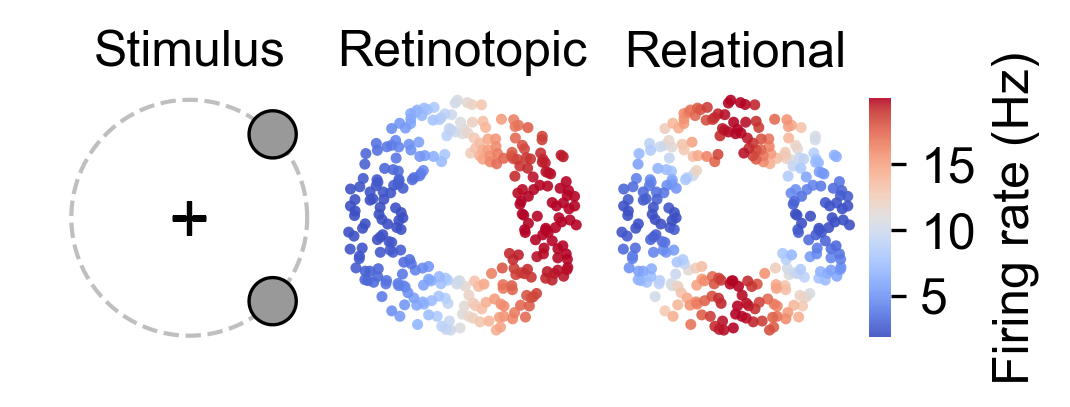

In [5]:
# Column layout. Every colorbar gets a column OF ITS OWN, so no ring panel is shrunk by
# carrying one and the panels stay directly comparable in size.
n_rings = len(TABLES)
ratios, ring_cols, cbar_cols = [RING_WIDTH_RATIO_STIM], [], []
for k in range(n_rings):
    ring_cols.append(len(ratios)); ratios.append(1.0)
    if not SHARE_COLOR_SCALE:
        cbar_cols.append(len(ratios)); ratios.append(CBAR_COLUMN)
if SHARE_COLOR_SCALE:
    cbar_cols.append(len(ratios)); ratios.append(CBAR_COLUMN)

fig = plt.figure(figsize=FIGSIZE_RING)
gs = fig.add_gridspec(1, len(ratios), width_ratios=ratios)

ax_stim = fig.add_subplot(gs[0, 0], projection='polar')
if RING_TRANSPARENT:
    ax_stim.patch.set_visible(False)
sl.plot_stimulus_ring(THETA0, THETA1, ax=ax_stim, disc_radius=STIM_DISC_RADIUS,
                      disc_color=STIM_DISC_COLOR, view=STIM_VIEW, title='Stimulus')

# One colour scale across the panels when SHARE_COLOR_SCALE, so their colours mean the same
# thing — which is the point of putting the families side by side.
ALL_VALUES = np.concatenate([t[COLOR_VALUE].to_numpy(float) for t in TABLES.values()])
CENTER = (COLOR_CENTER if COLOR_CENTER is not None else
          (1.0 if COLOR_VALUE == 'ratio'
           else float(np.median(np.concatenate(
               [t.groupby('unit_row')['baseline'].first().to_numpy(float)
                for t in TABLES.values()])))))
NORM = (sl.diverging_norm(ALL_VALUES, COLOR_VMIN, COLOR_VMAX, CENTER, CLIP_PERCENTILE)
        if SHARE_COLOR_SCALE else None)

mappables, ring_axes = [], []
for col, (title, table) in zip(ring_cols, TABLES.items()):
    ax = fig.add_subplot(gs[0, col], projection='polar')
    if RING_TRANSPARENT:
        ax.patch.set_visible(False)     # so a negative RING_WSPACE cannot paint over a neighbour
    ring_axes.append(ax)
    _, _, sc = sl.plot_rf_ring(
        table, THETA0, THETA1, ax=ax, cmap=CMAP, center=CENTER, norm=NORM,
        value=COLOR_VALUE, vmin=COLOR_VMIN, vmax=COLOR_VMAX,
        clip_percentile=CLIP_PERCENTILE,
        # r_outer / view match the stimulus panel's ring radius and axis limit, so the
        # rings in all three panels are the same circle drawn at the same size.
        r_outer=1.0, view=STIM_VIEW,
        jitter=JITTER, seed=JITTER_SEED, point_size=POINT_SIZE, point_alpha=POINT_ALPHA,
        sort_by_abs=SORT_BY_ABS, angle_labels=ANGLE_LABELS,
        stim_radius=STIM_DISC_RADIUS, stim_lw=STIM_CIRCLE_LW, stim_ls=STIM_CIRCLE_LS,
        stim_color=STIM_CIRCLE_COLOR, show_stim=SHOW_RING_GUIDES,
        show_ring=SHOW_RING_GUIDES, title=title, colorbar=False)
    mappables.append(sc)

caxes = []
for col, sc in zip(cbar_cols, mappables[-len(cbar_cols):]):
    cax = fig.add_subplot(gs[0, col])
    cb = fig.colorbar(sc, cax=cax)
    cb.set_label(CBAR_LABEL)
    cb.outline.set_visible(False)
    caxes.append(cax)

fig.tight_layout()
if RING_WSPACE is not None:
    fig.subplots_adjust(wspace=RING_WSPACE)   # after tight_layout, which would override it
# One height for every title. A polar axes and a plain one place their titles differently by
# default, so setting y explicitly is what keeps them on one line.
for ax in fig.axes:
    if ax.get_title():
        # `set_title(..., y=)` rather than `title.set_y(...)`: only the former clears the
        # axes' auto-title-position flag, and while that flag is set matplotlib recomputes
        # the position at draw time and silently discards anything set on the Text itself —
        # so TITLE_Y appeared to do nothing at all.
        ax.set_title(ax.get_title(), y=TITLE_Y, fontsize=TITLE_FONTSIZE)

# Size the colorbars LAST — tight_layout would overwrite any position set before it. Both
# knobs are fractions of a ring panel's box, and the bar is centred on that panel vertically.
ref = ring_axes[0].get_position()
for cax in caxes:
    box = cax.get_position()
    w, h = ref.width * CBAR_WIDTH, ref.height * CBAR_HEIGHT
    cax.set_position([box.x0 + ref.width * CBAR_X, ref.y0 + (ref.height - h) / 2, w, h])

fig.savefig(OUTPUT_PDF, bbox_inches='tight', pad_inches=0.01)
print(f'saved {OUTPUT_PDF}')
plt.show()